<a href="https://colab.research.google.com/github/rutu019/MLT_practice/blob/main/EXP9_Implementation_of_SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Implementation of Support Vector Machine**

SVM works by mapping data to a higj-dimensional feature space so that data points can be categorized, even when the data are not otherwise linearly separable(This gets done by kernel function of SVM classifier). A separator between the categories is found,then the data is transformed in such a way that the separator could be drawn as a hyperplane.

**Step 1 : Importing Libraries**

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

**Step 2 : Reading the dataset**

In [2]:

df = pd.read_csv("/content/drive/MyDrive/Social_Network_Ads.csv")

In [3]:
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [4]:
df.shape

(400, 5)

In [5]:
df.size #gives size in bites

2000

In [6]:
df.count()

,0
User ID,400
Gender,400
Age,400
EstimatedSalary,400
Purchased,400


**Step 3 : Exploring the data**

In [7]:
# identifying unwanted rows
df.dtypes

,0
User ID,int64
Gender,object
Age,int64
EstimatedSalary,int64
Purchased,int64


In [8]:
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


The column where datatype is object is non numeric that means we can not apply numerical operations on these particular columns

In [9]:
x = df.iloc[:, [2, 3]].values
y = df.iloc[:, 4].values

In [10]:
x[:5]

array([[   19, 19000],
       [   35, 20000],
       [   26, 43000],
       [   27, 57000],
       [   19, 76000]])

**Step 4 : Spliting data into train test split**

In [11]:
from sklearn.model_selection import train_test_split

In [12]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.3,random_state=1)

**Step 5 : Data Scaling**

In [13]:
from sklearn.preprocessing import StandardScaler
sc_x = StandardScaler()
x_train = sc_x.fit_transform(x_train)
x_test = sc_x.transform(x_test)

A kernel in a SVM is a mathematical function that takes low-dimensional input data and transform it into a higher-dimensional space.Its primary purpose is to help the SVM find a linear decision boundary (a hyperplane) for datasets that are not linearly separable in their original space.

**Step 6: Model Training**

In [14]:
from sklearn.svm import SVC
classifier = SVC(kernel = 'linear', random_state = 0)
classifier.fit(x_train, y_train)

SVC(kernel='linear', random_state=0)

In [17]:
y_pred = classifier.predict(x_test)

In [18]:
y_pred

array([0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1,
       1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0,
       1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1,
       0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

**Visualize a graph and hyperplane**

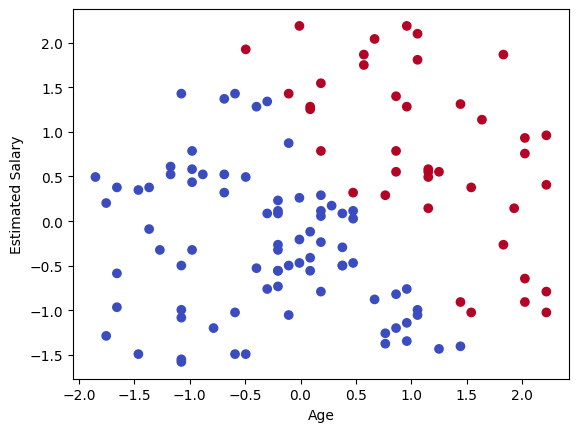

In [21]:
plt.scatter(x_test[:, 0], x_test[:, 1], c=y_pred, cmap='coolwarm')
plt.xlabel('Age'); plt.ylabel('Estimated Salary')
plt.show()

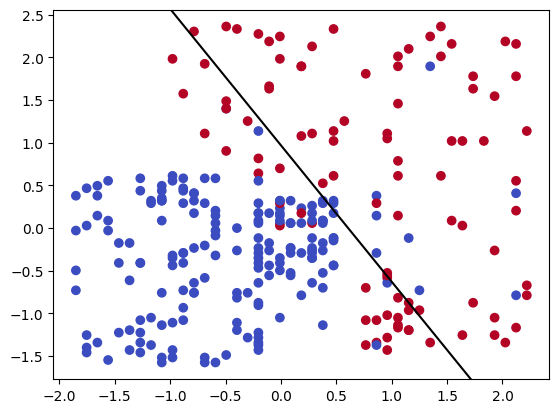

In [26]:
plt.scatter(x_train[:,0], x_train[:,1], c=y_train, cmap='coolwarm')
plt.axline((0, -classifier.intercept_[0]/classifier.coef_[0][1]), slope=-classifier.coef_[0][0]/classifier.coef_[0][1], color='black')
plt.show()